# Residual connections and normalization: companion notebook

**AI 4200 Deep Learning, Week 6.1.** Every variance written on the lecture's stream diagrams (2σ², 4σ², …, 1.25σ², σ² + l) is an exact result for a block with He initialization. This notebook builds those residual blocks from real random matrices, pushes data through them forward and backward, and measures the same quantities, so you can see the formulas hold.

- **Runtime:** under a minute on a CPU; a GPU is used if one is available. No downloads.
- **What to expect:** the measured values come from random matrices, so they match the slides to within a few percent (at most about 6% here), not exactly. The closed-form results (the products and limits on the Converging variance slides) are checked exactly.
- **Not reproduced here:** the four plot images on the Variance Forward Pass, Variance Backward Pass, Final norm for scaling and Stable at depth slides come from the instructor's own experiment, linked on the Stable at depth slide.

In [1]:
import math

import matplotlib.pyplot as plt
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

SEED = 0
NUM_EXAMPLES = 4096   # e: rows of X (examples)
NUM_FEATURES = 256    # f: width of the residual stream (features)
NUM_NEURONS = 1024    # n: hidden width inside each block (neurons)
NUM_BLOCKS = 4        # L: the four blocks drawn on the slides
SIGMA2 = 1.0          # σ² = Var(X₀)

BLUE, ORANGE, INK, GREY = "#2557D6", "#C2510F", "#16181D", "#8E94A0"

device: cpu


## Shared helpers

One residual block is `· W_inᵀ → ReLU → · W_outᵀ`. On the slides block l's weights are W₂ₗ₋₁ (here `W_in`, n×f) and W₂ₗ (here `W_out`, f×n). He initialization gives `W_in` variance 2/f, so its ReLU output keeps the input's second moment, and `W_out` variance 1/n, so the block hands back the variance it read.

In [2]:
def make_block(generator):
    # Weights are drawn on the CPU so every device sees the same numbers.
    W_in = torch.randn(NUM_NEURONS, NUM_FEATURES, generator=generator) * math.sqrt(2 / NUM_FEATURES)
    W_out = torch.randn(NUM_FEATURES, NUM_NEURONS, generator=generator) * math.sqrt(1 / NUM_NEURONS)
    return W_in.to(device), W_out.to(device)


def make_input(generator, sigma2=SIGMA2):
    """X₀: an e×f matrix with independent N(0, σ²) entries."""
    X = torch.randn(NUM_EXAMPLES, NUM_FEATURES, generator=generator) * math.sqrt(sigma2)
    return X.to(device)


def block_forward(X, W_in, W_out):
    """Linear → ReLU → Linear. Returns the ReLU input Ŷ, the ReLU output P̂ and the block output."""
    y_hat = X @ W_in.T
    p_hat = torch.relu(y_hat)
    out = p_hat @ W_out.T
    return y_hat, p_hat, out


def norm(X, eps=1e-5):
    """LayerNorm with γ = 1 and β = 0: every row (one example) gets mean 0 and variance 1."""
    return torch.nn.functional.layer_norm(X, (X.shape[1],), eps=eps)


def run_stream(blocks, X, scale=None, pre_norm=False):
    """Push X through residual blocks and record the variances shown on the stream diagrams.

    scale(l) multiplies block l's output before the add; pre_norm puts a Norm at the start of each block.
    """
    rows = []
    for l, (W_in, W_out) in enumerate(blocks, start=1):
        block_input = norm(X) if pre_norm else X
        y_hat, p_hat, out = block_forward(block_input, W_in, W_out)
        if scale is not None:
            out = scale(l) * out
        X = X + out
        rows.append({
            "block": l,
            "var_y_hat": y_hat.var().item(),
            "p_hat_second_moment": (p_hat ** 2).mean().item(),   # E[P̂²]; P̂ is not zero-mean
            "var_added": out.var().item(),
            "var_stream": X.var().item(),
        })
    return rows, X


def print_table(rows, columns):
    """Print measured values next to the slide's values: columns is a list of (title, key, slide_values)."""
    header = f"{'block':>5}" + "".join(f"  {title:>24}" for title, _, _ in columns)
    print(header)
    for i, row in enumerate(rows):
        cells = "".join(f"  {row[key]:>11.3f} (slide {slide[i]:>7.3f})" for _, key, slide in columns)
        print(f"{row['block']:>5}" + cells)

## Forward Pass

One pass through the four blocks with the shapes from the slide: the stream Xₗ stays e×f, while Ŷₗ and P̂ₗ inside each block are e×n.

In [3]:
generator = torch.Generator().manual_seed(SEED)
blocks = [make_block(generator) for _ in range(NUM_BLOCKS)]
X = make_input(generator)
print("X0:", tuple(X.shape))
for l, (W_in, W_out) in enumerate(blocks, start=1):
    y_hat, p_hat, out = block_forward(X, W_in, W_out)
    X = X + out
    print(f"block {l}: W_in {tuple(W_in.shape)}  Y_hat {tuple(y_hat.shape)}  P_hat {tuple(p_hat.shape)}  "
          f"W_out {tuple(W_out.shape)}  X{l} {tuple(X.shape)}")

X0: (4096, 256)
block 1: W_in (1024, 256)  Y_hat (4096, 1024)  P_hat (4096, 1024)  W_out (256, 1024)  X1 (4096, 256)
block 2: W_in (1024, 256)  Y_hat (4096, 1024)  P_hat (4096, 1024)  W_out (256, 1024)  X2 (4096, 256)
block 3: W_in (1024, 256)  Y_hat (4096, 1024)  P_hat (4096, 1024)  W_out (256, 1024)  X3 (4096, 256)


block 4: W_in (1024, 256)  Y_hat (4096, 1024)  P_hat (4096, 1024)  W_out (256, 1024)  X4 (4096, 256)


## Variance Forward Pass

Each block returns the variance it reads, and the identity path keeps the stream's own variance, so every add doubles it: Var(Xₗ) = 2ˡσ². Inside block l, Var(Ŷ) is twice the block's input variance and E[P̂²] is half of that.

In [4]:
generator = torch.Generator().manual_seed(SEED)
blocks = [make_block(generator) for _ in range(NUM_BLOCKS)]
rows, _ = run_stream(blocks, make_input(generator))
print_table(rows, [
    ("Var(Y_hat)", "var_y_hat", [2.0, 4.0, 8.0, 16.0]),
    ("E[P_hat^2]", "p_hat_second_moment", [1.0, 2.0, 4.0, 8.0]),
    ("Var(block out)", "var_added", [1.0, 2.0, 4.0, 8.0]),
    ("Var(X_l)", "var_stream", [2.0, 4.0, 8.0, 16.0]),
])

block                Var(Y_hat)                E[P_hat^2]            Var(block out)                  Var(X_l)
    1        1.997 (slide   2.000)        0.999 (slide   1.000)        0.937 (slide   1.000)        1.927 (slide   2.000)
    2        3.846 (slide   4.000)        1.951 (slide   2.000)        1.962 (slide   2.000)        3.959 (slide   4.000)
    3        7.888 (slide   8.000)        3.923 (slide   4.000)        3.909 (slide   4.000)        8.114 (slide   8.000)
    4       16.149 (slide  16.000)        7.819 (slide   8.000)        8.047 (slide   8.000)       16.899 (slide  16.000)


## Backward Pass and Variance Backward Pass

Autograd computes every gradient on the backward-pass slide. Choosing L = Σ X₄ ⊙ G with G ~ N(0, σ²) makes ∂L/∂X₄ = G, so the upstream gradient has variance σ². Going back through each block doubles it, reaching Var(∂L/∂X₀) = 2⁴σ². With f = 256 and n = 1024, f/n = 0.25.

In [5]:
generator = torch.Generator().manual_seed(SEED)
blocks = [make_block(generator) for _ in range(NUM_BLOCKS)]
X0 = make_input(generator).requires_grad_(True)

X = X0
stream = [X0]
inside = []
for W_in, W_out in blocks:
    y_hat, p_hat, out = block_forward(X, W_in, W_out)
    y_hat.retain_grad()
    p_hat.retain_grad()
    X = X + out
    X.retain_grad()
    stream.append(X)
    inside.append((y_hat, p_hat))

upstream = (torch.randn(X.shape, generator=generator) * math.sqrt(SIGMA2)).to(device)   # ∂L/∂X₄
loss = (X * upstream).sum()
loss.backward()

f_over_n = NUM_FEATURES / NUM_NEURONS
print(f"f/n = {f_over_n}")
print(f"{'':>10}{'measured':>12}{'slide':>10}")
for l in range(NUM_BLOCKS, -1, -1):
    slide = 2.0 ** (NUM_BLOCKS - l) * SIGMA2
    print(f"{'dL/dX' + str(l):>10}{stream[l].grad.var().item():>12.3f}{slide:>10.3f}")

print()
print(f"{'block':>5}{'Var(dL/dP_hat)':>18}{'slide':>9}{'Var(dL/dY_hat)':>18}{'slide':>9}")
for l, (y_hat, p_hat) in enumerate(inside, start=1):
    incoming = 2.0 ** (NUM_BLOCKS - l) * SIGMA2          # Var(∂L/∂Xₗ) arriving at block l
    print(f"{l:>5}{p_hat.grad.var().item():>18.4f}{f_over_n * incoming:>9.4f}"
          f"{y_hat.grad.var().item():>18.4f}{0.5 * f_over_n * incoming:>9.4f}")

f/n = 0.25
              measured     slide
    dL/dX4       1.000     1.000
    dL/dX3       1.997     2.000
    dL/dX2       3.975     4.000
    dL/dX1       7.990     8.000
    dL/dX0      15.968    16.000

block    Var(dL/dP_hat)    slide    Var(dL/dY_hat)    slide
    1            2.0053   2.0000            1.0037   1.0000
    2            0.9946   1.0000            0.4994   0.5000
    3            0.5004   0.5000            0.2484   0.2500
    4            0.2509   0.2500            0.1237   0.1250


## Where the scaling factor goes

One block with α = 0.5 and an input of variance 1. All three placements add the same total, (α² + 1)·Var(Xₗ₋₁) = 1.25, but option (c) gets there by shrinking what the stream already carried (the identity part), which is why it is the one to avoid. (a) and (b) agree because ReLU commutes with a positive scale.

In [6]:
alpha = 0.5
generator = torch.Generator().manual_seed(SEED)
W_in, W_out = make_block(generator)
X_prev = make_input(generator)

_, _, out_a = block_forward(alpha * X_prev, W_in, W_out)   # (a) scale the block input
_, _, out_b = block_forward(X_prev, W_in, W_out)           # (b) scale the block output
options = {
    "(a) scale the block input": (X_prev, out_a),
    "(b) scale the block output": (X_prev, alpha * out_b),
    "(c) scale the stream": (alpha * X_prev, out_b),
}
print(f"{'option':<28}{'identity part':>15}{'block adds':>12}{'Var(X_l)':>10}")
for name, (identity_part, added) in options.items():
    total = identity_part + added
    print(f"{name:<28}{identity_part.var().item():>15.3f}{added.var().item():>12.3f}{total.var().item():>10.3f}")
print(f"slide: (alpha^2 + 1) * Var(X_l-1) = {alpha ** 2 + 1:.3f}")

option                        identity part  block adds  Var(X_l)
(a) scale the block input             0.999       0.235     1.230
(b) scale the block output            0.999       0.235     1.230
(c) scale the stream                  0.250       0.938     1.184
slide: (alpha^2 + 1) * Var(X_l-1) = 1.250


## Converging variance

Scaling block l's output by 1/√l makes every block add exactly σ², so Var(Xₗ) = (l + 1)σ². Scaling every block by the same 1/√L multiplies the variance by (1 + 1/L) per block, giving (1 + 1/L)ᴸσ² = 2.44σ² for L = 4.

In [7]:
generator = torch.Generator().manual_seed(SEED)
blocks = [make_block(generator) for _ in range(NUM_BLOCKS)]
X0 = make_input(generator)

rows_l, _ = run_stream(blocks, X0, scale=lambda l: 1 / math.sqrt(l))
print("multiplier 1/sqrt(l)")
print_table(rows_l, [
    ("Var(block out)", "var_added", [1.0, 1.0, 1.0, 1.0]),
    ("Var(X_l)", "var_stream", [2.0, 3.0, 4.0, 5.0]),
])

rows_L, _ = run_stream(blocks, X0, scale=lambda l: 1 / math.sqrt(NUM_BLOCKS))
print("\nmultiplier 1/sqrt(L), L = 4")
print_table(rows_L, [
    ("Var(block out)", "var_added", [0.25, 0.31, 0.39, 0.49]),
    ("Var(X_l)", "var_stream", [1.25, 1.56, 1.95, 2.44]),
])

multiplier 1/sqrt(l)
block            Var(block out)                  Var(X_l)
    1        0.937 (slide   1.000)        1.927 (slide   2.000)
    2        0.981 (slide   1.000)        2.958 (slide   3.000)
    3        0.971 (slide   1.000)        4.041 (slide   4.000)
    4        1.013 (slide   1.000)        5.199 (slide   5.000)

multiplier 1/sqrt(L), L = 4
block            Var(block out)                  Var(X_l)
    1        0.234 (slide   0.250)        1.228 (slide   1.250)
    2        0.307 (slide   0.310)        1.549 (slide   1.560)
    3        0.382 (slide   0.390)        1.967 (slide   1.950)
    4        0.483 (slide   0.490)        2.501 (slide   2.440)


The two results on these slides are exact, so they can be checked without any randomness: the product ∏(1 + 1/l) telescopes to L + 1, and (1 + 1/L)ᴸ climbs toward e without reaching it.

In [8]:
from fractions import Fraction

for L in [1, 4, 16, 256]:
    product = 1
    for l in range(1, L + 1):
        product *= 1 + Fraction(1, l)
    print(f"L = {L:>3}: prod (1 + 1/l) = {product}  (L + 1 = {L + 1})")

print()
for L in [4, 16, 256, 10 ** 6]:
    print(f"L = {L:>7}: (1 + 1/L)^L = {(1 + 1 / L) ** L:.6f}  < e = {math.e:.6f}")

L =   1: prod (1 + 1/l) = 2  (L + 1 = 2)
L =   4: prod (1 + 1/l) = 5  (L + 1 = 5)
L =  16: prod (1 + 1/l) = 17  (L + 1 = 17)
L = 256: prod (1 + 1/l) = 257  (L + 1 = 257)

L =       4: (1 + 1/L)^L = 2.441406  < e = 2.718282
L =      16: (1 + 1/L)^L = 2.637928  < e = 2.718282
L =     256: (1 + 1/L)^L = 2.712992  < e = 2.718282
L = 1000000: (1 + 1/L)^L = 2.718280  < e = 2.718282


## Batch Norm and Layer Norm for automatic variance control

The same matrix (columns with different means and spreads) goes through PyTorch's norms with γ = 1, β = 0 and through the formulas on the slides. BatchNorm standardizes each column (feature) over the batch, LayerNorm each row (example) over its features. In `eval()` mode BatchNorm switches to its running statistics, so its output is no longer standardized after only one training batch.

In [9]:
generator = torch.Generator().manual_seed(SEED)
feature_means = torch.linspace(-3, 3, NUM_FEATURES)
feature_scales = torch.linspace(0.5, 4, NUM_FEATURES)
X = (torch.randn(NUM_EXAMPLES, NUM_FEATURES, generator=generator) * feature_scales + feature_means).to(device)
eps = 1e-5

batch_norm = torch.nn.BatchNorm1d(NUM_FEATURES, eps=eps, affine=False).to(device)
layer_norm = torch.nn.LayerNorm(NUM_FEATURES, eps=eps, elementwise_affine=False).to(device)

batch_norm.train()
Y_batch = batch_norm(X)
Y_layer = layer_norm(X)

# The formulas on the slides, written out by hand
mu_column = X.mean(dim=0)
var_column = X.var(dim=0, unbiased=False)
manual_batch = (X - mu_column) / torch.sqrt(var_column + eps)
mu_row = X.mean(dim=1, keepdim=True)
var_row = X.var(dim=1, unbiased=False, keepdim=True)
manual_layer = (X - mu_row) / torch.sqrt(var_row + eps)

print("max |BatchNorm - formula|:", (Y_batch - manual_batch).abs().max().item())
print("max |LayerNorm - formula|:", (Y_layer - manual_layer).abs().max().item())
print("BatchNorm column means in", [round(v, 3) for v in (Y_batch.mean(0).min().item(), Y_batch.mean(0).max().item())],
      "column variances in", [round(v, 3) for v in (Y_batch.var(0, unbiased=False).min().item(), Y_batch.var(0, unbiased=False).max().item())])
print("LayerNorm row means in", [round(v, 3) for v in (Y_layer.mean(1).min().item(), Y_layer.mean(1).max().item())],
      "row variances in", [round(v, 3) for v in (Y_layer.var(1, unbiased=False).min().item(), Y_layer.var(1, unbiased=False).max().item())])

batch_norm.eval()
with torch.no_grad():
    Y_eval = batch_norm(X)
print("BatchNorm in eval() mode, column variances in",
      [round(v, 3) for v in (Y_eval.var(0, unbiased=False).min().item(), Y_eval.var(0, unbiased=False).max().item())])

max |BatchNorm - formula|: 7.3909759521484375e-06
max |LayerNorm - formula|: 9.5367431640625e-07
BatchNorm column means in [-0.0, 0.0] column variances in [1.0, 1.0]
LayerNorm row means in [-0.0, 0.0] row variances in [1.0, 1.0]
BatchNorm in eval() mode, column variances in [0.285, 6.425]


## Forward variance with added normalization and Normalizing the output

With a Norm at the start of each block, every block reads variance 1 and adds exactly 1, whatever the stream holds: Var(Xₗ) = σ² + l. σ² = 4 here so the "+ l" stands apart from the 1/√l case above. The final Norm branches off the stream, so the output has variance 1 while X₄ still carries σ² + 4.

In [10]:
sigma2_demo = 4.0
generator = torch.Generator().manual_seed(SEED)
blocks = [make_block(generator) for _ in range(NUM_BLOCKS)]
rows_norm, X_last = run_stream(blocks, make_input(generator, sigma2=sigma2_demo), pre_norm=True)
print_table(rows_norm, [
    ("Var(Y_hat)", "var_y_hat", [2.0, 2.0, 2.0, 2.0]),
    ("E[P_hat^2]", "p_hat_second_moment", [1.0, 1.0, 1.0, 1.0]),
    ("Var(block out)", "var_added", [1.0, 1.0, 1.0, 1.0]),
    ("Var(X_l)", "var_stream", [sigma2_demo + l for l in range(1, 5)]),
])
print(f"\nVar(X4) = {X_last.var().item():.3f} (slide sigma^2 + 4 = {sigma2_demo + 4})")
print(f"Var(Norm(X4)), the network's output = {norm(X_last).var().item():.3f} (slide 1)")

block                Var(Y_hat)                E[P_hat^2]            Var(block out)                  Var(X_l)
    1        2.001 (slide   2.000)        1.001 (slide   1.000)        0.939 (slide   1.000)        4.916 (slide   5.000)
    2        1.995 (slide   2.000)        1.006 (slide   1.000)        1.001 (slide   1.000)        5.967 (slide   6.000)
    3        1.994 (slide   2.000)        0.989 (slide   1.000)        0.983 (slide   1.000)        7.066 (slide   7.000)
    4        1.992 (slide   2.000)        0.981 (slide   1.000)        0.985 (slide   1.000)        8.171 (slide   8.000)

Var(X4) = 8.171 (slide sigma^2 + 4 = 8.0)
Var(Norm(X4)), the network's output = 1.000 (slide 1)


## Stream variance against depth

The four rules from the lecture side by side: the curves are the slide formulas for a network of depth L (σ² = 1), and the dots are measured from networks built and run here. Only the unscaled residual stream explodes; 1/√l and pre-norm grow linearly (with σ² = 1 they are the same line, so the dashed pre-norm curve hides the grey one), and 1/√L stays below e.

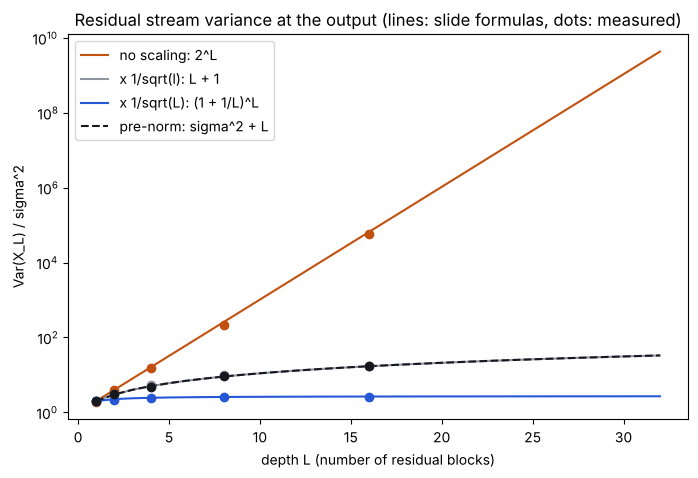

In [11]:
def output_variance(depth, rule, generator):
    """Var(X_L) at the end of a freshly initialized network of the given depth."""
    blocks = [make_block(generator) for _ in range(depth)]
    X0 = make_input(generator)
    if rule == "plain":
        rows, _ = run_stream(blocks, X0)
    elif rule == "1/sqrt(l)":
        rows, _ = run_stream(blocks, X0, scale=lambda l: 1 / math.sqrt(l))
    elif rule == "1/sqrt(L)":
        rows, _ = run_stream(blocks, X0, scale=lambda l: 1 / math.sqrt(depth))
    else:
        rows, _ = run_stream(blocks, X0, pre_norm=True)
    return rows[-1]["var_stream"]


formulas = {
    "plain": lambda L: 2.0 ** L,
    "1/sqrt(l)": lambda L: L + 1.0,
    "1/sqrt(L)": lambda L: (1 + 1 / L) ** L,
    "pre-norm": lambda L: SIGMA2 + L,
}
labels = {
    "plain": "no scaling: 2^L",
    "1/sqrt(l)": "x 1/sqrt(l): L + 1",
    "1/sqrt(L)": "x 1/sqrt(L): (1 + 1/L)^L",
    "pre-norm": "pre-norm: sigma^2 + L",
}
styles = {"plain": (ORANGE, "-"), "1/sqrt(l)": (GREY, "-"), "1/sqrt(L)": (BLUE, "-"), "pre-norm": (INK, "--")}

depth_curve = list(range(1, 33))
depth_measured = [1, 2, 4, 8, 16]
generator = torch.Generator().manual_seed(SEED)

fig, ax = plt.subplots(figsize=(8, 5))
for rule, formula in formulas.items():
    color, linestyle = styles[rule]
    ax.plot(depth_curve, [formula(L) for L in depth_curve], color=color, linestyle=linestyle, label=labels[rule])
    measured = [output_variance(L, rule, generator) for L in depth_measured]
    ax.scatter(depth_measured, measured, color=color, zorder=3)
ax.set_yscale("log")
ax.set_xlabel("depth L (number of residual blocks)")
ax.set_ylabel("Var(X_L) / sigma^2")
ax.set_title("Residual stream variance at the output (lines: slide formulas, dots: measured)")
ax.legend()
plt.show()